# 2001 — Echo State Networks and Reservoir Computing

**Papers:** Herbert Jaeger, *"The 'echo state' approach to analysing and training recurrent neural networks"*, GMD Report 148 (2001); Jaeger & Haas, *"Harnessing Nonlinearity: Predicting Chaotic Systems and Saving Energy in Wireless Communication"*, Science (2004). In parallel: Maass, Natschläger & Markram, *Liquid State Machines* (2002).

In 2001 training recurrent networks with backpropagation through time was slow and unstable (notebooks 11 and 13). The echo state network's answer was radical: **do not train the recurrent weights at all.**

- Build a large, random, fixed recurrent network: the **reservoir**, $h_t = \tanh(W h_{t-1} + W_{in} u_t)$.
- Train only a **linear readout** $y_t = W_{out} h_t$ by ridge regression, a single linear solve.

It works if the reservoir has the **echo state property**: its state must depend on the input history and forget its own initial condition. The practical knob is the **spectral radius** $\rho(W)$, the largest absolute eigenvalue. Near (just below) 1, the reservoir keeps a long fading memory of its input.

The 2004 Science paper predicted the chaotic Mackey–Glass system orders of magnitude more accurately than earlier methods. We reproduce a small version of that.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


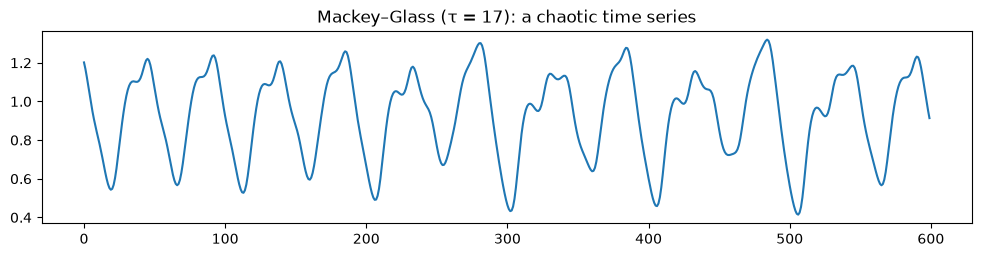

In [2]:
def mackey_glass(n, tau=17, beta=0.2, gamma=0.1, p=10, dt=0.1, seed=0):
    """Mackey–Glass delay differential equation, integrated with Euler sub-steps, sampled every 1 time unit."""
    rng = np.random.default_rng(seed)
    hist = int(tau / dt); x = list(1.2 + 0.1 * rng.standard_normal(hist + 1))
    out = []
    for i in range(int(n / dt) + 3000):
        xt, xd = x[-1], x[-hist - 1]
        x.append(xt + dt * (beta * xd / (1 + xd ** p) - gamma * xt))
        if i % int(1 / dt) == 0: out.append(x[-1])
    return np.array(out[300:300 + n])                                  # drop the transient
series = mackey_glass(5000)
plt.figure(figsize=(12, 2.5)); plt.plot(series[:600]); plt.title("Mackey–Glass (τ = 17): a chaotic time series"); plt.show()

In [3]:
class ESN:
    def __init__(self, n=500, rho=0.9, density=0.05, in_scale=0.5, leak=1.0, seed=0):
        rng = np.random.default_rng(seed)
        W = rng.uniform(-1, 1, (n, n)) * (rng.random((n, n)) < density)
        W *= rho / np.max(np.abs(np.linalg.eigvals(W)))                  # set the spectral radius exactly
        self.W, self.Win, self.leak, self.n = W, rng.uniform(-in_scale, in_scale, (n, 2)), leak, n   # input + bias
    def run(self, u, h=None):
        h = np.zeros(self.n) if h is None else h; H = []
        for x in u:
            h = (1 - self.leak) * h + self.leak * np.tanh(self.W @ h + self.Win @ np.array([x, 1.0]))
            H.append(h)
        return np.array(H), h
    def fit(self, u, y, washout=200, ridge=1e-6):
        H, self.h_last = self.run(u)
        H, y = H[washout:], y[washout:]
        self.Wout = np.linalg.solve(H.T @ H + ridge * np.eye(self.n), H.T @ y)   # the only training: one linear solve
        return np.sqrt(np.mean((H @ self.Wout - y) ** 2)) / np.std(y)
    def generate(self, x0, steps):
        """Free run: feed the network's own prediction back as the next input."""
        h, x, out = self.h_last.copy(), x0, []
        for _ in range(steps):
            h = (1 - self.leak) * h + self.leak * np.tanh(self.W @ h + self.Win @ np.array([x, 1.0]))
            x = h @ self.Wout; out.append(x)
        return np.array(out)

## The echo state property
Run the same reservoir twice on the same input, starting from two very different states. With $\rho<1$ the two trajectories merge: the state is a function of the input history alone. With $\rho$ well above 1 the reservoir's own dynamics dominate and the initial state is never forgotten.

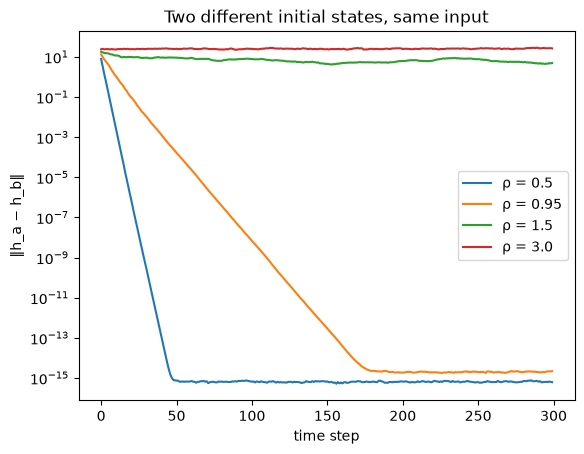

In [4]:
u = series[:300] - series.mean()
for rho in [0.5, 0.95, 1.5, 3.0]:
    esn = ESN(rho=rho)
    rng = np.random.default_rng(1)
    Ha, _ = esn.run(u, h=rng.uniform(-1, 1, esn.n)); Hb, _ = esn.run(u, h=rng.uniform(-1, 1, esn.n))
    d = np.linalg.norm(Ha - Hb, axis=1)
    plt.semilogy(d + 1e-16, label=f"ρ = {rho}")
plt.xlabel("time step"); plt.ylabel("‖h_a − h_b‖"); plt.title("Two different initial states, same input"); plt.legend(); plt.show()

## Learning Mackey–Glass with one linear solve
Train the readout to predict $x_{t+1}$ from the reservoir state after 2,000 steps. Then **free-run** the trained network for 500 steps, feeding its own predictions back, and compare with the true continuation.

training took 0.16s (no backprop, no recurrent-weight training); one-step train NRMSE 1.5e-04
free-running NRMSE over the first  84 steps: 0.004
free-running NRMSE over the first 200 steps: 0.017
free-running NRMSE over the first 500 steps: 0.362


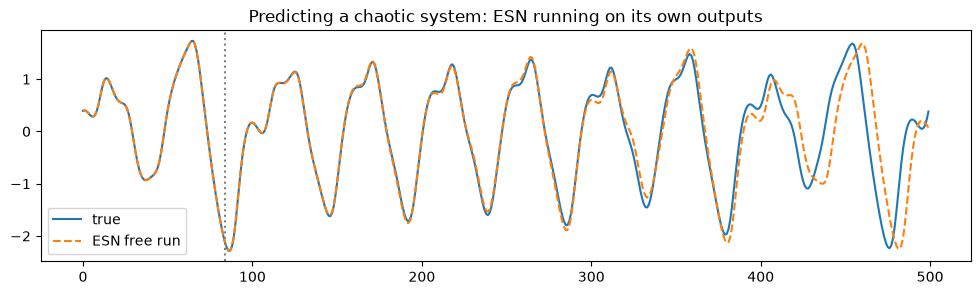

In [5]:
mu, sd = series.mean(), series.std()
z = (series - mu) / sd
train_len, test_len = 2000, 500
t0 = time.time()
esn = ESN(rho=0.95, seed=0)
nrmse_train = esn.fit(z[:train_len], z[1:train_len + 1])
gen = esn.generate(z[train_len], test_len)
truth = z[train_len + 1:train_len + 1 + test_len]
print(f"training took {time.time() - t0:.2f}s (no backprop, no recurrent-weight training); one-step train NRMSE {nrmse_train:.1e}")
for horizon in [84, 200, 500]:
    print(f"free-running NRMSE over the first {horizon:3d} steps: {np.sqrt(np.mean((gen[:horizon] - truth[:horizon]) ** 2)):.3f}")
plt.figure(figsize=(12, 3)); plt.plot(truth, label="true"); plt.plot(gen, "--", label="ESN free run")
plt.axvline(84, c="gray", ls=":"); plt.legend(); plt.title("Predicting a chaotic system: ESN running on its own outputs"); plt.show()

## Spectral radius sweep
How far ahead does the free-running prediction stay accurate (error below 0.2 of the series' standard deviation)? Averaged over 3 random reservoirs per setting.

In [6]:
for rho in [0.3, 0.6, 0.9, 0.95, 1.1, 1.3, 1.6, 2.0]:
    hs = []
    for seed in range(3):
        e = ESN(rho=rho, seed=seed); e.fit(z[:train_len], z[1:train_len + 1])
        err = np.abs(e.generate(z[train_len], test_len) - truth)
        bad = np.where(err > 0.2)[0]; hs.append(bad[0] if len(bad) else test_len)
    print(f"ρ = {rho:4.2f}: accurate for {np.mean(hs):5.0f} steps on average")

ρ = 0.30: accurate for    14 steps on average


ρ = 0.60: accurate for    76 steps on average


ρ = 0.90: accurate for   367 steps on average


ρ = 0.95: accurate for   354 steps on average


ρ = 1.10: accurate for   444 steps on average


ρ = 1.30: accurate for   368 steps on average


ρ = 1.60: accurate for    19 steps on average


ρ = 2.00: accurate for     2 steps on average


## Takeaways
- **Random features, trained readout.** The reservoir is a fixed, nonlinear, fading-memory feature map of the input history; all learning is one ridge regression.
- **Spectral radius** controls the memory: too small (0.3–0.6) and the network forgets too fast to model the delay; around 1 (0.9–1.3 here) works best; beyond ~1.5 the reservoir's own dynamics take over, the echo state property is lost, and predictions fail within a few steps.
- **Legacy:** reservoir computing lives on in neuromorphic and physical computing (optical, spintronic reservoirs). The idea of a fixed, well-conditioned linear recurrence with a trained readout also foreshadows the structured state-space models (S4, Mamba; notebook 59), whose recurrences are initialised carefully for long memory and then *also* trained.